# Кластеризация ЕГЭ

## 1. Подготовка

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

cluster_counts = [2, 3, 2, 3, 2, 3]
colors = ["royalblue", "darkorange", "seagreen"]

all_points = []
all_labels = []
all_medoids = []

## 2. Разделение кластеров прямыми

- Таблица 0: `A = (0; 8)`, `B = (2.1; 5.4)`, `M_AB = (1.05; 6.7)`.`y = 0.80769*x + 5.85385`.
- Таблица 1:
  - `A = (6.7; 2.2)` и `B = (8; -1)`, `M_AB = (7.35; 0.6)`: `y = 0.40625*x - 2.38594`;
  - `A = (6.7; 2.2)` и `C = (10; 1.2)`, `M_AC = (8.35; 1.7)`: `y = 3.3*x - 25.855`;
  - `B = (8; -1)` и `C = (10; 1.2)`, `M_BC = (9; 0.1)`: `y = -0.90909*x + 8.28182`.
- Таблица 2: `P = (22.380578; 3.708712)`, `Q = (24.746198; -6.659354)`,  `M = (23.563388; -1.475321)`. `x = 23.56339`.
- Таблица 3:
  - `P1 = (-15.327695; -17.541032)`, `P2 = (-6.347569; 9.234043)`, `M12 = (-10.837632; -4.153494)`: `x = -10.83763`;
  - `P3 = (13.620933; 2.341534)`, `P4 = (20.764966; -7.847834)`, `M34 = (17.192949; -2.753150)`: `x = 17.19295`.
- Таблица 4: `A = (0; 7)`, `B = (5; 3)`, `M_AB = (2.5; 5)`. `y = 1.25*x + 1.875`.
- Таблица 5:
  - `A = (-3; 0.5)` и `B = (-1; 7)`, `M_AB = (-2; 3.75)`: `y = -0.30769*x + 3.13462`;
  - `B = (-1; 7)` и `C = (4; 3)`, `M_BC = (1.5; 5)`: `y = 1.25*x + 3.125`;
  - `A = (-3; 0.5)` и `C = (4; 3)`, `M_AC = (0.5; 1.75)`: `y = -2.8*x + 3.15`.

In [77]:
for file_number in range(6):
    table = pd.read_csv("data/" + str(file_number) + ".csv")
    points = table[["X", "Y"]].values
    labels = []

    for point in points:
        x = point[0]
        y = point[1]

        if file_number == 0:
            if y > 0.8077 * x + 5.8538:
                label = 0
            else:
                label = 1

        elif file_number == 1:
            line_01 = 0.40625 * x - 2.38594
            line_02 = 3.3 * x - 25.855
            line_12 = 8.28182 - 0.90909 * x

            if y > line_01 and y > line_02:
                label = 0
            elif y < line_01 and y < line_12:
                label = 1
            else:
                label = 2

        elif file_number == 2:
            if x < 23.56339:
                label = 0
            else:
                label = 1

        elif file_number == 3:
            if x < -10.83763:
                label = 0
            elif x < 17.19295:
                label = 1
            else:
                label = 2

        elif file_number == 4:
            if y > 1.25 * x + 1.875:
                label = 0
            else:
                label = 1

        else:
            line_01 = 3.13462 - 0.30769 * x
            line_02 = 1.25 * x + 3.125
            line_12 = 3.15 - 2.8 * x

            if y < line_01 and y < line_12:
                label = 0
            elif y > line_01 and y > line_02:
                label = 1
            else:
                label = 2

        labels.append(label)

    all_points.append(points)
    all_labels.append(np.array(labels))

print("OKAY")

OKAY


## 3. Медоиды и итоговые координаты

In [74]:
for file_number in range(6):
    points = all_points[file_number]
    labels = all_labels[file_number]
    manhattan = file_number == 3 or file_number == 4
    medoids = []

    for cluster_number in range(cluster_counts[file_number]):
        cluster = points[labels == cluster_number]
        distance_sums = []

        for point in cluster:
            differences = np.abs(cluster - point)

            if manhattan:
                distances = differences.sum(axis=1)
            else:
                distances = np.sqrt((differences ** 2).sum(axis=1))

            distance_sums.append(distances.sum())

        medoids.append(cluster[np.argmin(distance_sums)])

    all_medoids.append(medoids)
    mean_x = np.mean([point[0] for point in medoids]) * 1000
    mean_y = np.mean([point[1] for point in medoids]) * 1000
    print(f"Таблица {file_number}: X = {mean_x:.3f}, Y = {mean_y:.3f}")

Таблица 0: X = 1041.006, Y = 6671.173
Таблица 1: X = 8177.531, Y = 738.419
Таблица 2: X = 23130.216, Y = 635.342
Таблица 3: X = 3078.894, Y = -4758.945
Таблица 4: X = 2588.540, Y = 4996.568
Таблица 5: X = 61.652, Y = 3723.362


## 4. Исходные распределения

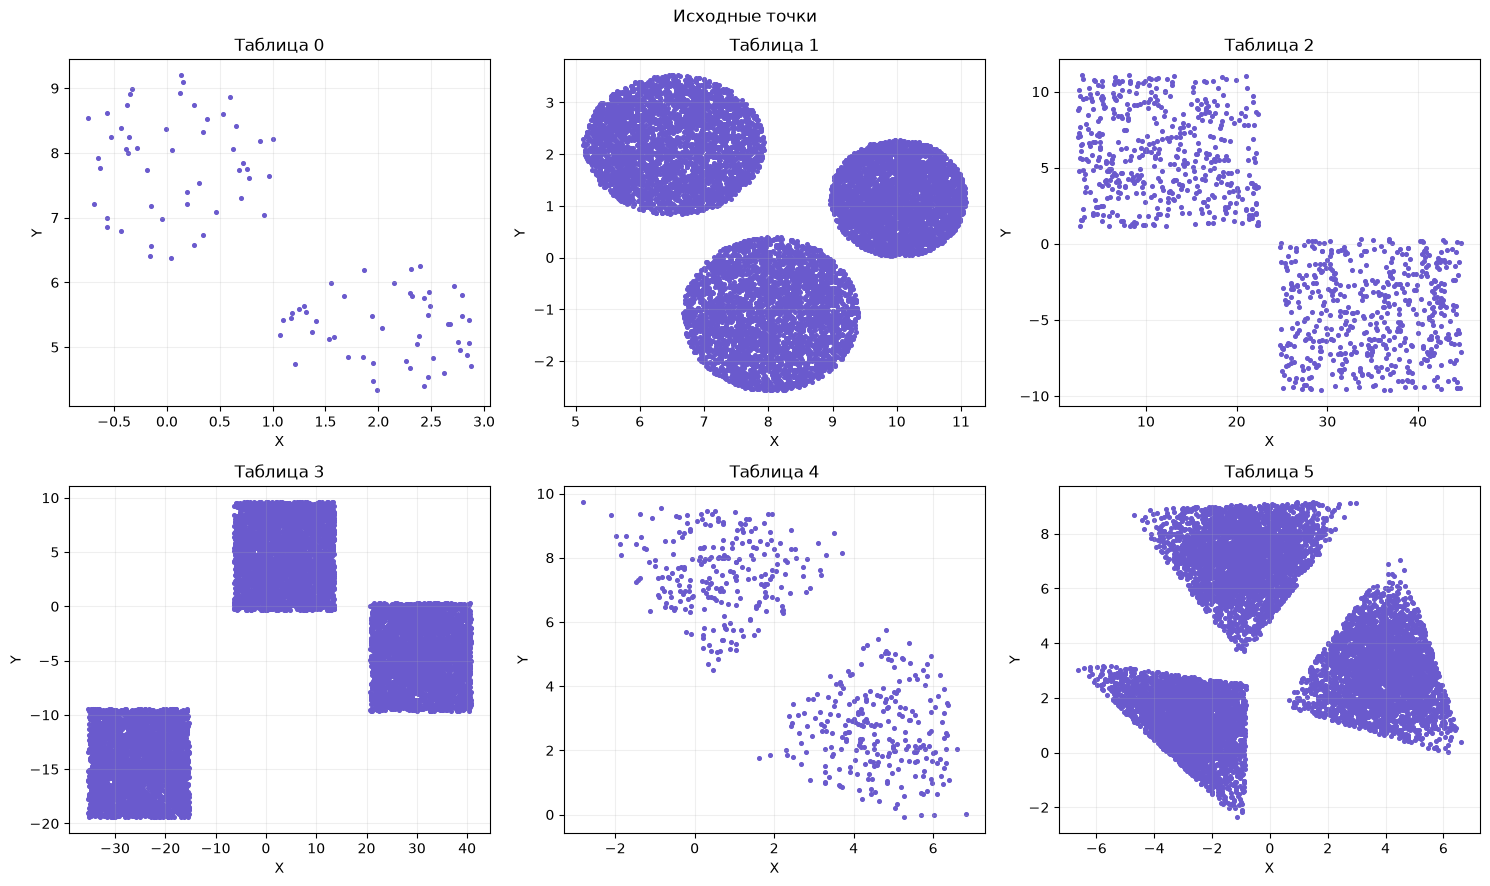

In [75]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for file_number, ax in enumerate(axes.flat):
    points = all_points[file_number]
    ax.scatter(points[:, 0], points[:, 1], s=7, color="slateblue")
    ax.set_title("Таблица " + str(file_number))
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(True, alpha=0.2)

fig.suptitle("Исходные точки")
plt.tight_layout()
plt.show()

## 5. Кластеры и медоиды

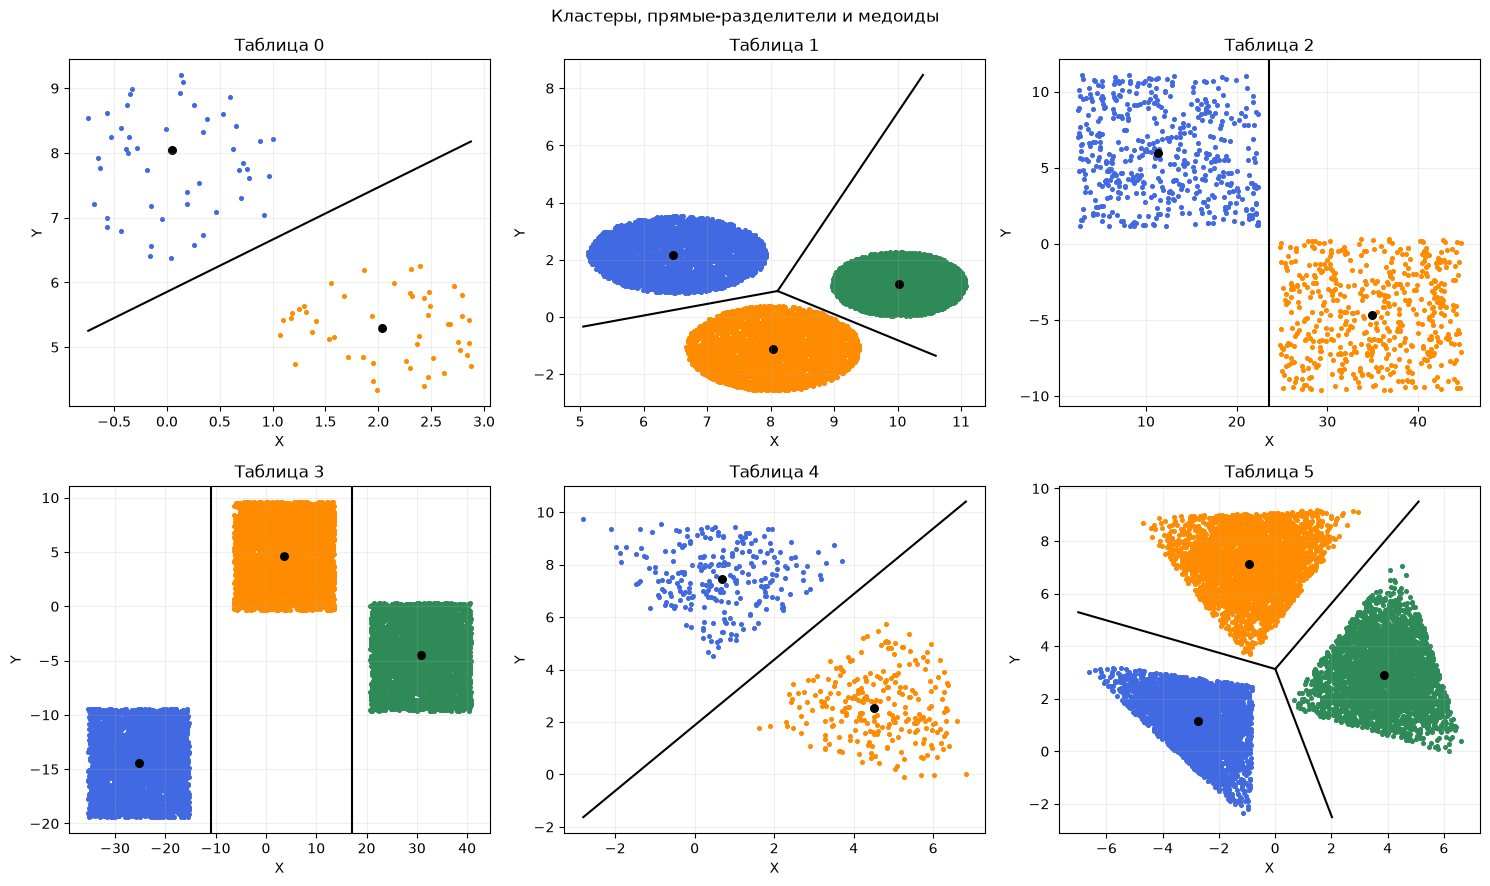

In [76]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for file_number, ax in enumerate(axes.flat):
    points = all_points[file_number]
    labels = all_labels[file_number]

    for cluster_number in range(cluster_counts[file_number]):
        cluster = points[labels == cluster_number]
        ax.scatter(
            cluster[:, 0],
            cluster[:, 1],
            s=7,
            color=colors[cluster_number]
        )

    medoids = np.array(all_medoids[file_number])
    ax.scatter(
        medoids[:, 0],
        medoids[:, 1],
        marker="o",
        s=30,
        color="black"
    )

    if file_number == 0:
        x1, x2 = points[:, 0].min(), points[:, 0].max()
        ax.plot(
            [x1, x2],
            [0.8077 * x1 + 5.8538, 0.8077 * x2 + 5.8538],
            color="black"
        )

    elif file_number == 1:
        ax.plot(
            [5.05, 8.1103],
            [0.40625 * 5.05 - 2.38594, 0.90886],
            color="black"
        )
        ax.plot(
            [8.1103, 10.4],
            [0.90886, 3.3 * 10.4 - 25.855],
            color="black"
        )
        ax.plot(
            [8.1103, 10.6],
            [0.90886, 8.28182 - 0.90909 * 10.6],
            color="black"
        )

    elif file_number == 2:
        ax.axvline(23.56339, color="black")

    elif file_number == 3:
        ax.axvline(-10.83763, color="black")
        ax.axvline(17.19295, color="black")

    elif file_number == 4:
        x1, x2 = points[:, 0].min(), points[:, 0].max()
        ax.plot(
            [x1, x2],
            [1.25 * x1 + 1.875, 1.25 * x2 + 1.875],
            color="black"
        )

    else:
        ax.plot([-7, 0.006], [5.29, 3.13], color="black")
        ax.plot(
            [0.006, 5.1],
            [3.13, 1.25 * 5.1 + 3.125],
            color="black"
        )
        ax.plot(
            [0.006, 2.02],
            [3.13, 3.15 - 2.8 * 2.02],
            color="black"
        )

    ax.set_title("Таблица " + str(file_number))
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(True, alpha=0.2)

fig.suptitle("Кластеры, прямые-разделители и медоиды")
plt.tight_layout()
plt.show()